# Otras formas de fechar la vía

El 1_ le da a cada parte de vía el año de la estación de Wikidata más cercana. Acá el fechado se
plantea como un problema de aprendizaje supervisado, suponiendo que estaciones y partes de vía son
intercambiables: un modelo aprende el año de las estaciones a partir de su posición y lo predice
para cada parte. Cada modelo elige su configuración con una validación cruzada sobre las estaciones, se mide por la curva de km en pie que produce contra el ONDaT y se mira, además, cómo
fecha todo el territorio.

## Datos

Todo del 1_, en `data/pipeline`:

- `vias.parquet` — `km`, `activo`, `alta`, `baja` y `geometry` de cada parte; `alta` y `baja` son
  las del 1-vecino del 1_.
- `estaciones.parquet` — `fuente`, `x`, `y`, `alta` y `baja`; se usan las de Wikidata con
  coordenadas.
- `ondat.csv` — `anio` y `red_km`, la red en servicio según el ONDaT.
- `provincias.parquet` — el mapa base y la máscara de la grilla.

In [17]:
# PyCharm elige un backend que abre ventana aparte sin esto.
%matplotlib inline

import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.spatial import cKDTree
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold
from pathlib import Path

PIPELINE = Path('data/pipeline')

ANIO_MIN, ANIO_MAX = 1857, 2025
PARTES = 5                       # estaciones: en cuántas partes al azar se divide la validación cruzada
PASO = 5                         # años: los cambios que se comparan con los del ONDaT
CELDA_KM = 10                    # km de lado de cada celda de la grilla
ESCALA_ANIOS = (1860, 2020)      # años: los extremos del color de alta y de baja
ESCALA_DIF = (-40, 0, 120)       # años: mínimo, centro y máximo del color de baja menos alta
SEMILLA = 0

vias = gpd.read_parquet(PIPELINE / 'vias.parquet')
estaciones = pd.read_parquet(PIPELINE / 'estaciones.parquet')
ondat = pd.read_csv(PIPELINE / 'ondat.csv')
provincias = gpd.read_parquet(PIPELINE / 'provincias.parquet')

wd = estaciones[(estaciones.fuente == 'Wikidata') & estaciones.x.notna()]
EST_ALTA = wd[wd.alta.notna()]
EST_BAJA = wd[wd.baja.notna()]
KM = vias.km.values
ACTIVO = vias.activo.values
print(f'{len(EST_ALTA)} estaciones con alta · {len(EST_BAJA)} con baja · {len(vias)} partes')

1706 estaciones con alta · 691 con baja · 7932 partes


Todos los modelos ven sólo la posición, x e y en km: cada parte de vía por su punto medio y cada
estación por su punto. Los mapas muestran lo que predice el modelo en todo el país y no sólo sobre
la traza, para ver la función entera que aprende.

In [18]:
def variables(x, y):
    return np.c_[x / 1000, y / 1000]

medio = vias.geometry.interpolate(.5, normalized=True)
X_PARTE = variables(medio.x.values, medio.y.values)
X_ALTA = variables(EST_ALTA.x.values, EST_ALTA.y.values)
X_BAJA = variables(EST_BAJA.x.values, EST_BAJA.y.values)

X0, Y0, X1, Y1 = provincias.total_bounds
xs = np.arange(X0, X1, CELDA_KM * 1000) + CELDA_KM * 500
ys = np.arange(Y0, Y1, CELDA_KM * 1000) + CELDA_KM * 500
gx, gy = np.meshgrid(xs, ys)
centros = gpd.GeoSeries(gpd.points_from_xy(gx.ravel(), gy.ravel()), crs=vias.crs)
EN_TIERRA = centros.within(provincias.union_all()).values
X_GRILLA = variables(gx.ravel()[EN_TIERRA], gy.ravel()[EN_TIERRA])
# Las celdas con vía, que son las únicas donde el fechado se usa.
puntos_via = np.concatenate([np.asarray(g.coords) for g in vias.geometry])
CON_VIA = cKDTree(puntos_via).query(np.c_[gx.ravel(), gy.ravel()][EN_TIERRA],
                                    distance_upper_bound=CELDA_KM * 1000)[0] < np.inf
print(f'{EN_TIERRA.sum()} celdas sobre tierra · {CON_VIA.sum()} con vía')

28026 celdas sobre tierra · 6431 con vía


## Cómo se juzga un modelo

La configuración del alta se elige sólo con las estaciones, por validación cruzada: se dividen al
azar en cinco partes, se entrena con cuatro y se mide el error al predecir la quinta. Gana la de
menor error sobre las cinco, y la baja se elige igual con las estaciones que tienen baja. El ONDaT
no participa de la elección. Con la curva de km en pie que resulta se mide el error cuadrático medio
contra el ONDaT y la correlación entre sus cambios a 5 años y los de la red real.

In [19]:
ANIOS = np.arange(ANIO_MIN, ANIO_MAX + 1)
EN_ONDAT = ondat.anio.values - ANIO_MIN
REAL = ondat.red_km.values
# El ONDaT no tiene 1934 ni 1936: para comparar cambios se interpola.
CONTINUO = np.arange(ANIO_MIN, ondat.anio.max() + 1)
REAL_CONTINUO = np.interp(CONTINUO, ondat.anio, REAL)

def curva(alta, baja):
    """Km en pie por año: construida y no dada de baja. La vía activa no tiene baja."""
    existe = alta[None, :] <= ANIOS[:, None]
    de_baja = existe & ~ACTIVO & (baja[None, :] <= ANIOS[:, None])
    return (existe & ~de_baja) @ KM

def corr_cambios(serie):
    s = serie[:len(CONTINUO)]
    return np.corrcoef(s[PASO:] - s[:-PASO], REAL_CONTINUO[PASO:] - REAL_CONTINUO[:-PASO])[0, 1]

def validacion_cruzada(construir, v, X, anios):
    """Raíz del error cuadrático medio, en años, al predecir cada parte con un modelo entrenado con las otras."""
    error = np.empty(len(anios))
    for entrena, prueba in KFold(PARTES, shuffle=True, random_state=SEMILLA).split(X):
        modelo = construir(v).fit(X[entrena], anios[entrena])
        error[prueba] = modelo.predict(X[prueba]) - anios[prueba]
    return np.sqrt((error ** 2).mean())

def predicciones(construir, valores, X, anios):
    """Una predicción por valor de la grilla: (etiqueta, año de cada parte, año de cada celda, error de validación)."""
    resultado = []
    for v in valores:
        modelo = construir(v).fit(X, anios)
        en_partes = np.clip(np.round(modelo.predict(X_PARTE)), ANIO_MIN, ANIO_MAX)
        en_grilla = np.clip(modelo.predict(X_GRILLA), ANIO_MIN, ANIO_MAX)
        resultado.append((f'{construir.__name__.replace("_", " ")} {v}', en_partes, en_grilla,
                          validacion_cruzada(construir, v, X, anios)))
    return resultado

ALTAS, BAJAS, ELEGIDO = {}, {}, {}

def elegir(nombre, altas, bajas):
    """Toma el alta y la baja de menor error de validación y mide su curva contra el ONDaT."""
    alta = altas[np.argmin([p[3] for p in altas])]
    baja = bajas[np.argmin([p[3] for p in bajas])]
    serie = curva(alta[1], baja[1])
    ELEGIDO[nombre] = {'alta': alta, 'baja': baja, 'curva': serie,
                       'ecm_ondat': ((serie[EN_ONDAT] - REAL) ** 2).mean() / 1e6,
                       'corr_cambios': corr_cambios(serie)}
    e = ELEGIDO[nombre]
    dif = baja[2] - alta[2]
    print(f'{nombre}: alta {alta[0]} · baja {baja[0]}')
    print(f'validación alta {alta[3]:.1f} · baja {baja[3]:.1f} años · ECM ONDaT {e["ecm_ondat"]:.1f} millones de km² · '
          f'corr. cambios {e["corr_cambios"]:.2f}')
    print(f'baja antes que alta en el {100 * (dif[CON_VIA] < 0).mean():.1f}% de las celdas con vía · '
          f'mediana de baja menos alta {np.median(dif[CON_VIA]):.0f} años')

def coma(x, decimales=1):
    return f'{x:.{decimales}f}'.replace('.', ',')

def numeros(e):
    return (f'validación alta {coma(e["alta"][3])} · baja {coma(e["baja"][3])} años · '
            f'ECM ONDaT {coma(e["ecm_ondat"])} M km² · corr. cambios {coma(e["corr_cambios"], 2)}')

def a_grilla(valores):
    plano = np.full(gx.size, np.nan)
    plano[EN_TIERRA] = valores
    return plano.reshape(gx.shape)

EXTENSION = (X0, xs[-1] + CELDA_KM * 500, Y0, ys[-1] + CELDA_KM * 500)
NORMA_DIF = TwoSlopeNorm(vmin=ESCALA_DIF[0], vcenter=ESCALA_DIF[1], vmax=ESCALA_DIF[2])
REFERENCIA = '1-vecino'

def dibujar(nombre):
    """Los tres mapas del modelo elegido y su curva contra el ONDaT."""
    e = ELEGIDO[nombre]
    fig, axs = plt.subplots(1, 4, figsize=(17, 6.6), gridspec_kw={'width_ratios': [1, 1, 1, 2.3]})
    capas = [(e['alta'][2], 'viridis', {'vmin': ESCALA_ANIOS[0], 'vmax': ESCALA_ANIOS[1]}, 'año de alta'),
             (e['baja'][2], 'viridis', {'vmin': ESCALA_ANIOS[0], 'vmax': ESCALA_ANIOS[1]}, 'año de baja'),
             (e['baja'][2] - e['alta'][2], 'RdBu', {'norm': NORMA_DIF}, 'baja menos alta')]
    for ax, (valores, colores, escala, titulo) in zip(axs, capas):
        imagen = ax.imshow(a_grilla(valores), origin='lower', extent=EXTENSION, cmap=colores,
                           interpolation='nearest', **escala)
        provincias.boundary.plot(ax=ax, color='white', linewidth=.25)
        vias.plot(ax=ax, color='black', linewidth=.15, alpha=.35)
        ax.set_xlim(X0, X1)
        ax.set_ylim(Y0, Y1)
        ax.set_aspect('equal', adjustable='box')
        ax.set_axis_off()
        ax.set_title(titulo, fontsize=10)
        fig.colorbar(imagen, ax=ax, orientation='horizontal', fraction=.035, pad=.02)
    ax = axs[3]
    ax.plot(ondat.anio, REAL / 1000, color='#898781', lw=3, alpha=.6, label='ONDaT')
    if nombre != REFERENCIA:
        ax.plot(ANIOS, ELEGIDO[REFERENCIA]['curva'] / 1000, color='#1b1b1b', lw=.9, ls='--', label=REFERENCIA)
    ax.plot(ANIOS, e['curva'] / 1000, color='#2a78d6', lw=1.6, label=nombre)
    ax.set_ylabel('miles de km en pie')
    ax.set_title(numeros(e), fontsize=10)
    ax.legend(frameon=False, loc='lower center')
    for lado in ('top', 'right'):
        ax.spines[lado].set_visible(False)
    fig.suptitle(nombre, x=.01, ha='left', fontsize=14, fontweight='bold')
    plt.show()

## 1-vecino

El del 1_: en las partes, los años que ya trae `vias.parquet`, medidos contra toda la línea; en la
grilla, la estación más cercana al centro de cada celda.

1-vecino: alta 1-vecino · baja 1-vecino
validación alta 30.1 · baja 18.5 años · ECM ONDaT 22.0 millones de km² · corr. cambios 0.86
baja antes que alta en el 0.7% de las celdas con vía · mediana de baja menos alta 89 años


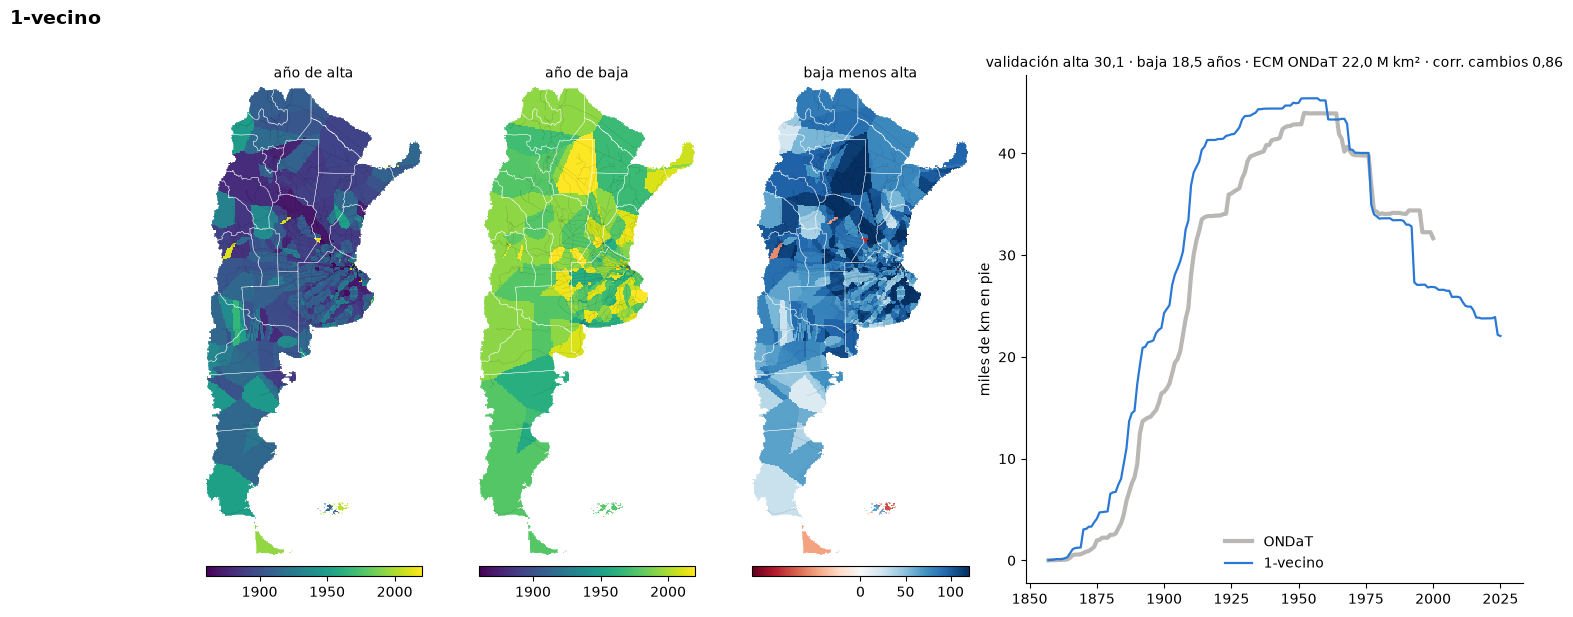

In [20]:
def vecino(k):
    return KNeighborsRegressor(n_neighbors=k)

grilla_alta = vecino(1).fit(X_ALTA, EST_ALTA.alta).predict(X_GRILLA)
grilla_baja = vecino(1).fit(X_BAJA, EST_BAJA.baja).predict(X_GRILLA)
ALTAS[REFERENCIA] = [('1-vecino', vias.alta.values, grilla_alta,
                      validacion_cruzada(vecino, 1, X_ALTA, EST_ALTA.alta.values))]
BAJAS[REFERENCIA] = [('1-vecino', vias.baja.values, grilla_baja,
                      validacion_cruzada(vecino, 1, X_BAJA, EST_BAJA.baja.values))]
elegir(REFERENCIA, ALTAS[REFERENCIA], BAJAS[REFERENCIA])
dibujar(REFERENCIA)

## k vecinos

La media de los años de las k estaciones más cercanas al punto medio de cada parte.

k vecinos: alta vecino 10 · baja vecino 3
validación alta 23.4 · baja 15.7 años · ECM ONDaT 26.7 millones de km² · corr. cambios 0.79
baja antes que alta en el 0.0% de las celdas con vía · mediana de baja menos alta 90 años


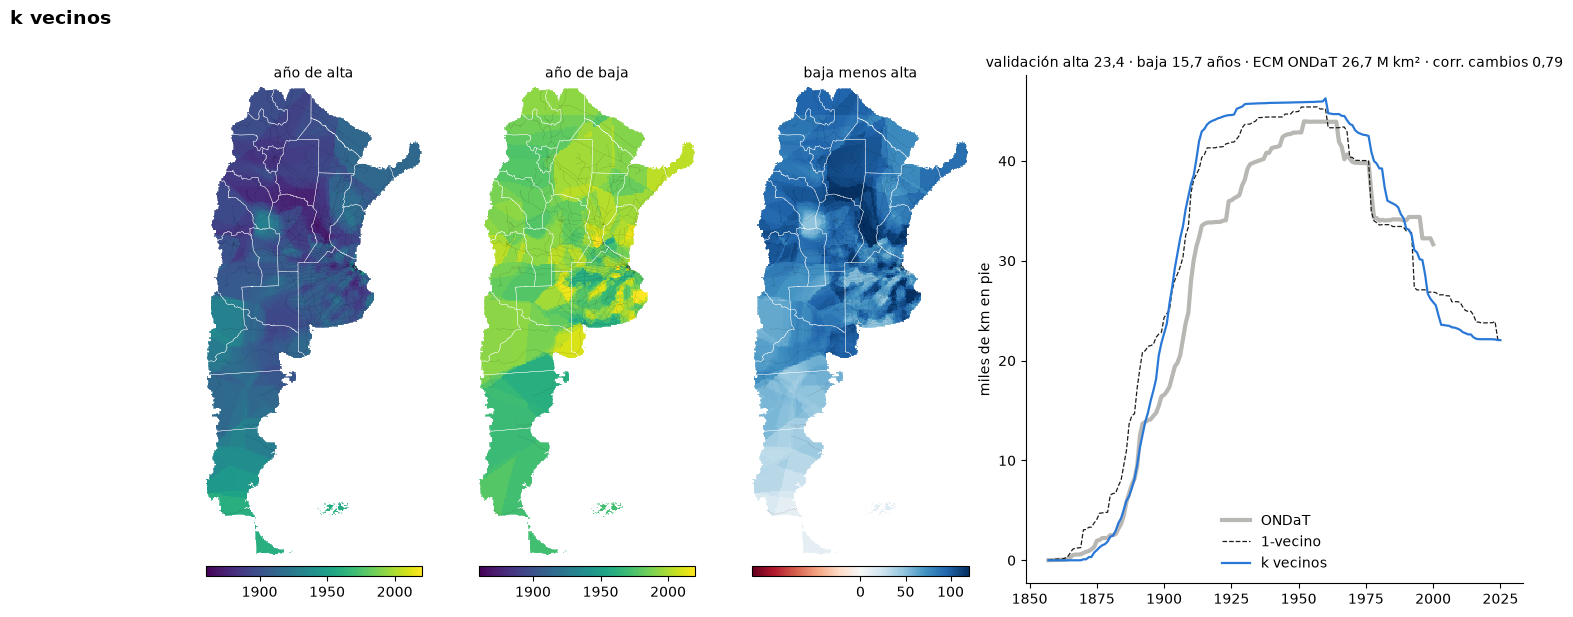

In [21]:
ALTAS['k vecinos'] = predicciones(vecino, [1, 2, 3, 5, 10, 20, 50], X_ALTA, EST_ALTA.alta.values)
BAJAS['k vecinos'] = predicciones(vecino, [1, 2, 3, 5, 10, 20, 50], X_BAJA, EST_BAJA.baja.values)
elegir('k vecinos', ALTAS['k vecinos'], BAJAS['k vecinos'])
dibujar('k vecinos')

## Red neuronal

Un perceptrón con entradas y año escalados, que con años crudos del orden de 1900 no converge. Se
prueban cuatro arquitecturas, de una capa de 8 a tres de 64.

/home/gonzalo_kubuntu/Desktop/Entrega/github/datasets_y_procesamiento_de_datos/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")
/home/gonzalo_kubuntu/Desktop/Entrega/github/datasets_y_procesamiento_de_datos/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


red neuronal: alta capas (64, 64, 64) · baja capas (64, 64, 64)
validación alta 24.7 · baja 17.5 años · ECM ONDaT 23.2 millones de km² · corr. cambios 0.76
baja antes que alta en el 0.6% de las celdas con vía · mediana de baja menos alta 81 años


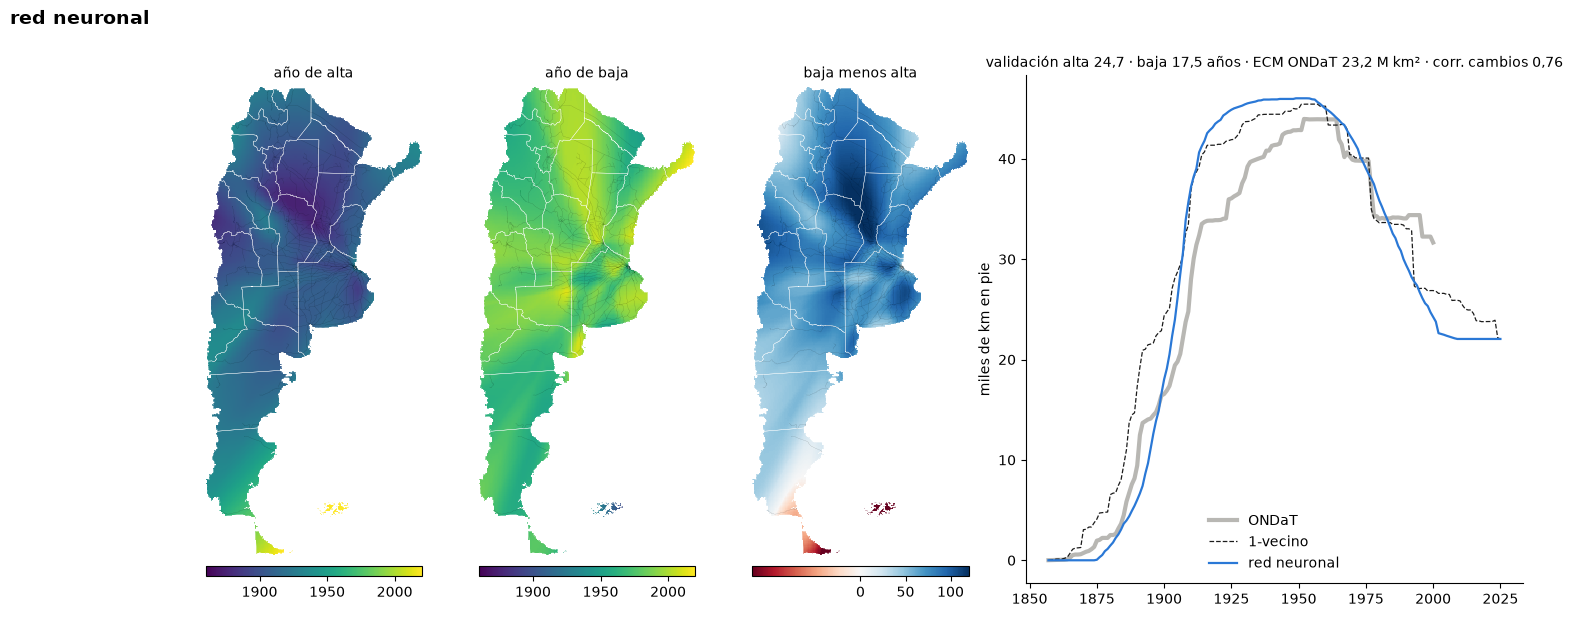

In [16]:
def capas(forma):
    red = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=forma, max_iter=2000, random_state=SEMILLA))
    return TransformedTargetRegressor(red, transformer=StandardScaler())

ALTAS['red neuronal'] = predicciones(capas, [(8,), (32,), (32, 32), (64, 64, 64)], X_ALTA, EST_ALTA.alta.values)
BAJAS['red neuronal'] = predicciones(capas, [(8,), (32,), (32, 32), (64, 64, 64)], X_BAJA, EST_BAJA.baja.values)
elegir('red neuronal', ALTAS['red neuronal'], BAJAS['red neuronal'])
dibujar('red neuronal')

## Gradient boosting

Árboles de decisión sumados, con la cantidad de iteraciones como lo único que se elige.

gradient boosting: alta iteraciones 25 · baja iteraciones 100
validación alta 24.2 · baja 17.7 años · ECM ONDaT 32.4 millones de km² · corr. cambios 0.67
baja antes que alta en el 0.0% de las celdas con vía · mediana de baja menos alta 91 años


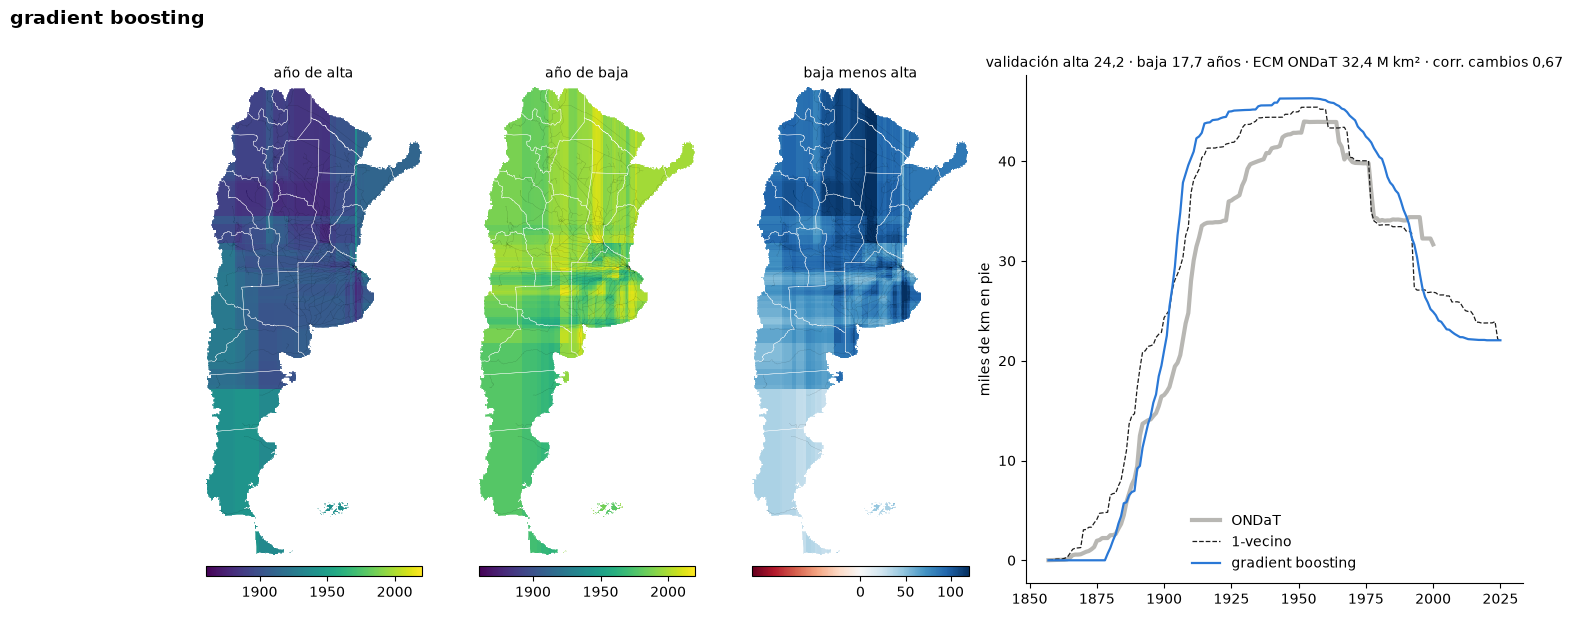

In [22]:
def iteraciones(n):
    return HistGradientBoostingRegressor(max_iter=n, random_state=SEMILLA)

ALTAS['gradient boosting'] = predicciones(iteraciones, [25, 50, 100, 200, 400, 800, 1600], X_ALTA, EST_ALTA.alta.values)
BAJAS['gradient boosting'] = predicciones(iteraciones, [25, 50, 100, 200, 400, 800, 1600], X_BAJA, EST_BAJA.baja.values)
elegir('gradient boosting', ALTAS['gradient boosting'], BAJAS['gradient boosting'])
dibujar('gradient boosting')

## Proceso gaussiano

Un núcleo RBF con la escala de largo fija, en km

proceso gaussiano: alta escala km 25 · baja escala km 25
validación alta 24.1 · baja 16.1 años · ECM ONDaT 31.7 millones de km² · corr. cambios 0.61
baja antes que alta en el 0.0% de las celdas con vía · mediana de baja menos alta 78 años


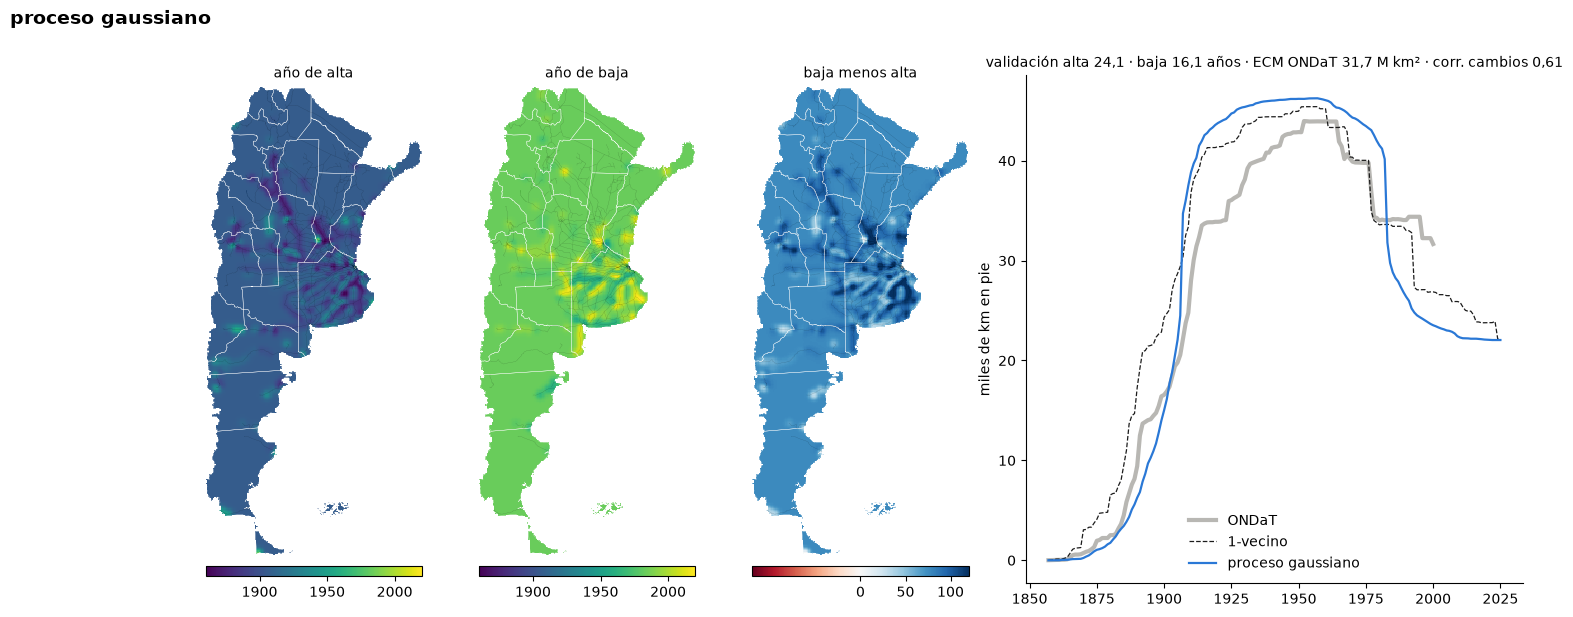

In [23]:
def escala_km(largo):
    return GaussianProcessRegressor(RBF(largo), alpha=.3, optimizer=None, normalize_y=True)

ALTAS['proceso gaussiano'] = predicciones(escala_km, [10, 25, 50, 100, 200, 400], X_ALTA, EST_ALTA.alta.values)
BAJAS['proceso gaussiano'] = predicciones(escala_km, [10, 25, 50, 100, 200, 400], X_BAJA, EST_BAJA.baja.values)
elegir('proceso gaussiano', ALTAS['proceso gaussiano'], BAJAS['proceso gaussiano'])
dibujar('proceso gaussiano')

## Mixto

El alta y la baja de menor error de validación entre todas las predicciones de arriba, aunque vengan
de modelos distintos.

mixto: alta k vecinos, vecino 10 · baja k vecinos, vecino 3
validación alta 23.4 · baja 15.7 años · ECM ONDaT 26.7 millones de km² · corr. cambios 0.79
baja antes que alta en el 0.0% de las celdas con vía · mediana de baja menos alta 90 años


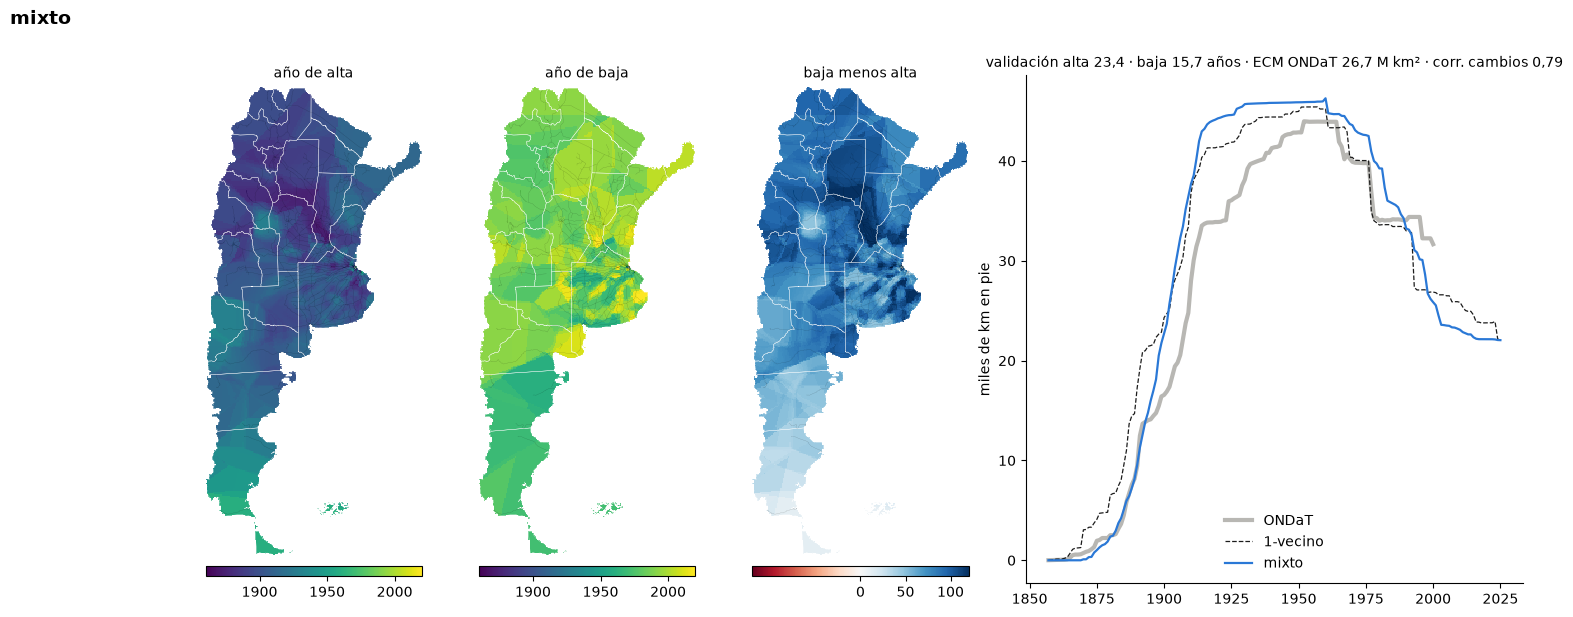

In [24]:
todas_altas, todas_bajas = [], []
for nombre in ALTAS:
    for etiqueta, en_partes, en_grilla, validacion in ALTAS[nombre]:
        todas_altas.append((f'{nombre}, {etiqueta}', en_partes, en_grilla, validacion))
    for etiqueta, en_partes, en_grilla, validacion in BAJAS[nombre]:
        todas_bajas.append((f'{nombre}, {etiqueta}', en_partes, en_grilla, validacion))
elegir('mixto', todas_altas, todas_bajas)
dibujar('mixto')

## Todos contra el ONDaT

Las curvas de los seis, cada una con el 1-vecino punteado de referencia.

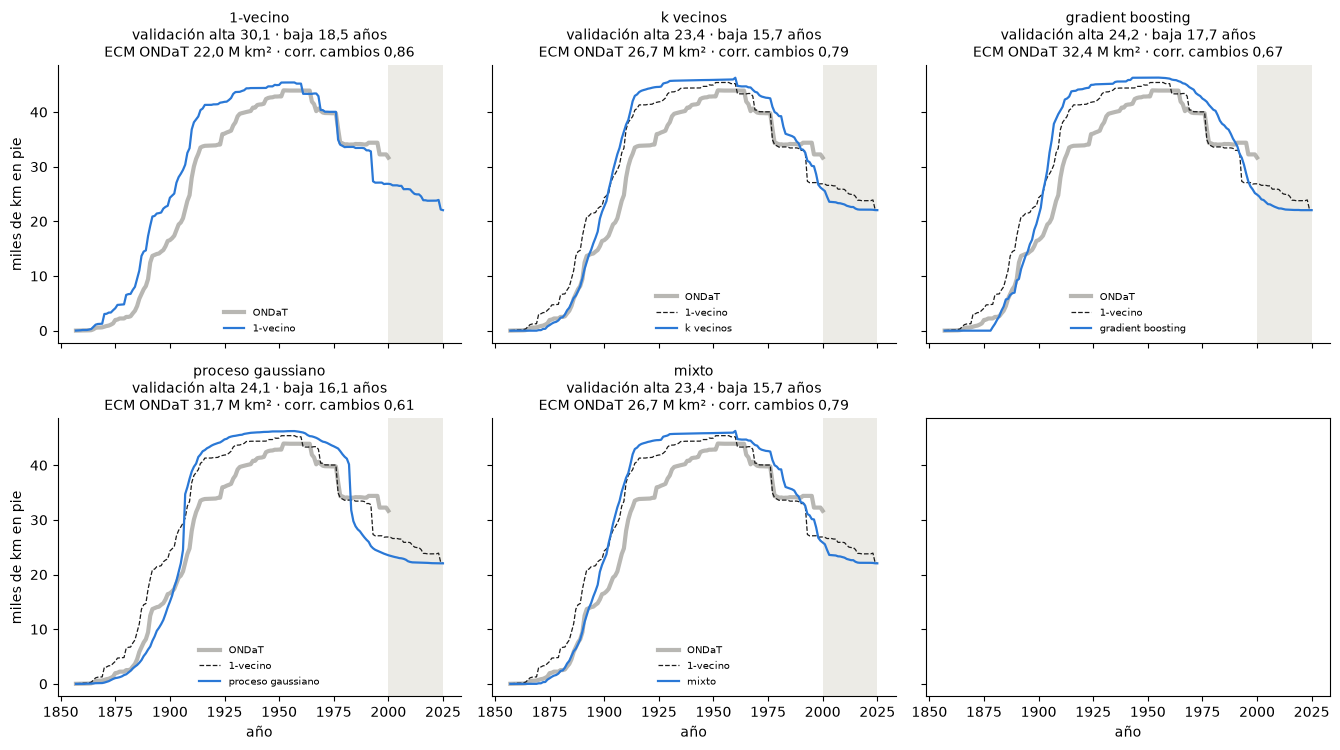

In [25]:
fig, axs = plt.subplots(2, 3, figsize=(13.5, 7.6), sharex=True, sharey=True)
for ax, (nombre, e) in zip(axs.flat, ELEGIDO.items()):
    ax.axvspan(ondat.anio.max(), ANIO_MAX, color='#ecebe6', lw=0)   # sin ONDaT: extrapolación
    ax.plot(ondat.anio, REAL / 1000, color='#898781', lw=3, alpha=.6, label='ONDaT')
    if nombre != REFERENCIA:
        ax.plot(ANIOS, ELEGIDO[REFERENCIA]['curva'] / 1000, color='#1b1b1b', lw=.9, ls='--', label=REFERENCIA)
    ax.plot(ANIOS, e['curva'] / 1000, color='#2a78d6', lw=1.6, label=nombre)
    ax.set_title(nombre + '\n' + numeros(e).replace(' años · ', ' años\n'), fontsize=10)
    ax.legend(loc='lower center', fontsize=7.5, frameon=False)
    for lado in ('top', 'right'):
        ax.spines[lado].set_visible(False)
for ax in axs[1]:
    ax.set_xlabel('año')
for ax in axs[:, 0]:
    ax.set_ylabel('miles de km en pie')
fig.tight_layout()
plt.show()